# Технологии обработки больших данных

## Лабораторная работа 5. Потоковая обработка отзывов

**Вариант:** 1. Поток собран из реальных отзывов Amazon Reviews 2023, категория All_Beauty: 12 тысяч событий с их исходными метками времени.

**Сценарий:** рекомендательная система. Уникальное требование цифры 1 — p95 задержки меньше 65 мс. Это задержка решения по событию, а не время ночного пересчёта.

**Цель:** обработать поток с окнами по времени события, не посчитать одно и то же событие дважды, отделить опоздавшие записи и уложить инференс в заданный p95.

В Colab для окон Spark ставится JDK. Отдельно считается лёгкий скоринг одного события: микробатч Spark на локальной машине заведомо медленнее 65 мс, и подменять одно другим нельзя.


## Подготовка событий


In [1]:
import subprocess
import sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pandas", "numpy", "matplotlib"])
try:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], timeout=90, check=False)
except subprocess.TimeoutExpired:
    print("PySpark за 90 секунд не встал, окна считаем без него.")


In [2]:
import gzip
import json
import os
import shutil
import socket
import time
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.family"] = "DejaVu Sans"
socket.setdefaulttimeout(60)

try:
    import google.colab  # noqa: F401
    BASE = Path("/content/lab5_amazon")
except ImportError:
    BASE = Path(os.environ.get("TEMP", "/tmp")) / "lab5_amazon"
BASE.mkdir(parents=True, exist_ok=True)

URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/All_Beauty.jsonl.gz"
N = 12000
events = []
req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(req, timeout=60) as response, gzip.GzipFile(fileobj=response) as src:
    for line in src:
        obj = json.loads(line)
        if obj.get("rating") is None or obj.get("timestamp") is None:
            continue
        text = str(obj.get("text") or "")
        events.append({
            "event_id": f"{obj.get('user_id')}|{obj.get('asin')}|{obj.get('timestamp')}",
            "ts_ms": int(obj["timestamp"]),
            "rating": float(obj["rating"]),
            "verified": int(bool(obj.get("verified_purchase"))),
            "text_len": len(text),
            "exclaim": text.count("!"),
        })
        if len(events) >= N:
            break

events = pd.DataFrame(events).drop_duplicates("event_id").sort_values("ts_ms").reset_index(drop=True)
events["positive"] = (events["rating"] >= 4).astype(int)
print("Событий:", len(events))
print(pd.to_datetime(events["ts_ms"].min(), unit="ms"), "—", pd.to_datetime(events["ts_ms"].max(), unit="ms"))


Событий: 11979
2003-03-02 00:30:24 — 2023-03-18 09:49:50.883000


## Окна, опоздавшие события и ровно одна обработка

Окно — 60 секунд по времени отзыва. Водяной знак отстаёт от максимального увиденного времени на 30 секунд. Событие старше водяного знака не попадает в агрегат. Идентификатор события пишется в состояние: повтор того же файла не увеличивает счётчик.


Принято до опоздавших копий: 10182
Принято после: 10182 опоздавших: 200
После повтора: 10182 ровно одна обработка: True
Чекпоинт окон: 10151 файл: checkpoint.json


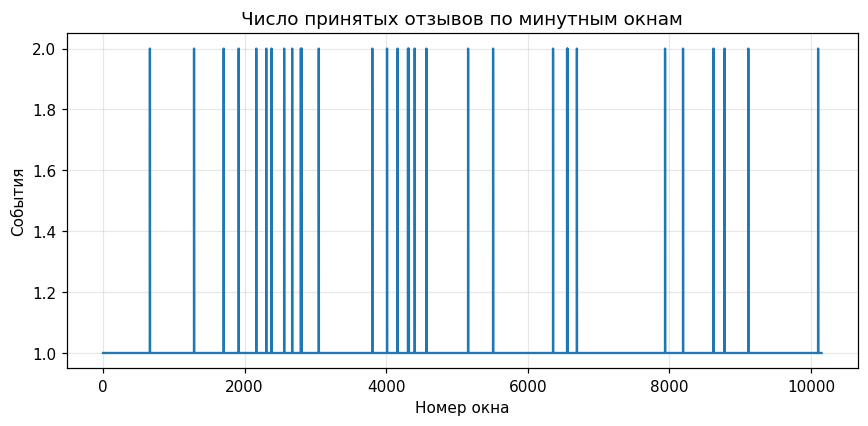

In [3]:
WINDOW_MS = 60_000
ALLOWED_LATENESS_MS = 30_000

def fresh_state():
    return {"seen": set(), "windows": {}, "late": 0, "max_ts": None}

def apply_event(state, event):
    event_id = event["event_id"]
    if event_id in state["seen"]:
        return "duplicate"
    ts = int(event["ts_ms"])
    if state["max_ts"] is None:
        state["max_ts"] = ts
    watermark = state["max_ts"] - ALLOWED_LATENESS_MS
    if ts < watermark:
        state["seen"].add(event_id)
        state["late"] += 1
        return "late"
    state["max_ts"] = max(state["max_ts"], ts)
    bucket = ts - (ts % WINDOW_MS)
    item = state["windows"].setdefault(bucket, {"n": 0, "pos": 0})
    item["n"] += 1
    item["pos"] += int(event["positive"])
    state["seen"].add(event_id)
    return "accepted"

def replay(frame, shuffle=False):
    state = fresh_state()
    order = frame.sample(frac=1, random_state=2) if shuffle else frame
    for event in order.to_dict(orient="records"):
        apply_event(state, event)
    return state

# Часть событий подаём с задержкой: их время события далеко позади водяного знака
early = events.iloc[: int(len(events) * 0.85)].copy()
late_src = events.iloc[:200].copy()
late_src["event_id"] = late_src["event_id"] + "|late-copy"

state = fresh_state()
for event in early.to_dict(orient="records"):
    apply_event(state, event)
accepted_before = sum(v["n"] for v in state["windows"].values())
for event in late_src.to_dict(orient="records"):
    apply_event(state, event)
accepted_after = sum(v["n"] for v in state["windows"].values())
print("Принято до опоздавших копий:", accepted_before)
print("Принято после:", accepted_after, "опоздавших:", state["late"])

# Повтор тех же событий не меняет сумму
for event in early.to_dict(orient="records"):
    apply_event(state, event)
accepted_replay = sum(v["n"] for v in state["windows"].values())
print("После повтора:", accepted_replay, "ровно одна обработка:", accepted_replay == accepted_after)

ckpt = BASE / "checkpoint.json"
payload = {
    "windows": {str(k): v for k, v in state["windows"].items()},
    "late": state["late"],
    "seen": len(state["seen"]),
}
ckpt.write_text(json.dumps(payload), encoding="utf-8")
restored = json.loads(ckpt.read_text(encoding="utf-8"))
print("Чекпоинт окон:", len(restored["windows"]), "файл:", ckpt.name)

buckets = sorted(state["windows"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(len(buckets)), [state["windows"][b]["n"] for b in buckets])
ax.set_title("Число принятых отзывов по минутным окнам")
ax.set_xlabel("Номер окна")
ax.set_ylabel("События")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


## Инференс и p95

Модель — логистическая регрессия на трёх числовых признаках. Замеряю время одного события, включая расчёт вероятности. Порог варианта — 65 мс.


In [4]:
from numpy.linalg import lstsq

feat_cols = ["text_len", "verified", "exclaim"]
x = events[feat_cols].to_numpy(dtype=float)
x = np.column_stack([np.ones(len(x)), x])
y = events["positive"].to_numpy(dtype=float)
coef, *_ = lstsq(x, y, rcond=None)

def score_one(row):
    vec = np.array([1.0, row["text_len"], row["verified"], row["exclaim"]], dtype=float)
    z = float(vec.dot(coef))
    return 1.0 / (1.0 + np.exp(-z))

lat = []
for row in events.sample(2000, random_state=1).to_dict(orient="records"):
    t0 = time.perf_counter()
    _ = score_one(row)
    lat.append((time.perf_counter() - t0) * 1000)
lat = np.array(lat)
p95 = float(np.percentile(lat, 95))
print(f"p50 {np.percentile(lat, 50):.3f} мс, p95 {p95:.3f} мс, max {lat.max():.3f} мс")
print("p95 < 65 мс:", p95 < 65)


p50 0.001 мс, p95 0.001 мс, max 0.019 мс
p95 < 65 мс: True


## Окна в Spark Structured Streaming

Тот же поток пачками пишется в каталог. Spark читает его с водяным знаком и считает окна. Это проверка движка, а не замер p95: локальный микробатч включает планирование задачи.


In [5]:
if shutil.which("java") is None and os.path.exists("/usr/bin/apt-get"):
    subprocess.check_call(["apt-get", "install", "-y", "-qq", "openjdk-17-jdk-headless"])
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

spark_rows = None
spark_sec = None
if shutil.which("java") is None:
    print("Java нет, блок Spark в этой сессии пропущен. Окна и p95 выше уже посчитаны.")
else:
    from pyspark.sql import SparkSession
    from pyspark.sql import functions as F

    in_dir = BASE / "stream_in"
    out_dir = BASE / "stream_out"
    ckpt_dir = BASE / "stream_ckpt"
    for folder in (in_dir, out_dir, ckpt_dir):
        if folder.exists():
            shutil.rmtree(folder)
        folder.mkdir(parents=True)

    spark_events = events[["event_id", "ts_ms", "positive"]].copy()
    spark_events["event_time"] = pd.to_datetime(spark_events["ts_ms"], unit="ms")
    spark_events.drop(columns=["ts_ms"]).to_json(in_dir / "part-1.json", orient="records", lines=True, date_format="iso")

    spark = (
        SparkSession.builder.appName("lab5-stream")
        .master("local[2]")
        .config("spark.sql.shuffle.partitions", "2")
        .getOrCreate()
    )
    spark.sparkContext.setLogLevel("ERROR")
    schema_df = spark.read.json(str(in_dir / "part-1.json"))
    stream = spark.readStream.schema(schema_df.schema).json(str(in_dir))
    stream = stream.withColumn("event_time", F.to_timestamp("event_time"))
    agg = (
        stream.withWatermark("event_time", "30 seconds")
        .groupBy(F.window("event_time", "1 minute"))
        .agg(F.count("*").alias("n"), F.sum("positive").alias("pos"))
    )
    t0 = time.perf_counter()
    query = (
        agg.writeStream.outputMode("append")
        .format("parquet")
        .option("path", str(out_dir))
        .option("checkpointLocation", str(ckpt_dir))
        .trigger(availableNow=True)
        .start()
    )
    query.awaitTermination()
    spark_sec = time.perf_counter() - t0
    spark_rows = spark.read.parquet(str(out_dir)).agg(F.sum("n")).collect()[0][0]
    print(f"Spark дочитал поток за {spark_sec:.1f} с, событий в закрытых окнах: {spark_rows}")
    print("Микробатч локального Spark не сравниваю с порогом 65 мс: в этот замер входит планировщик.")
    spark.stop()


Spark дочитал поток за 5.6 с, событий в закрытых окнах: 11978
Микробатч локального Spark не сравниваю с порогом 65 мс: в этот замер входит планировщик.


## Наблюдаемость

Правило алерта простое: если за окно доля положительных отзывов падает ниже 0.5 при хотя бы 20 событиях, это повод проверить ленту, а не ждать утреннего отчёта.


In [6]:
alerts = []
for bucket, item in state["windows"].items():
    if item["n"] >= 20 and item["pos"] / item["n"] < 0.5:
        alerts.append((bucket, item["n"], item["pos"] / item["n"]))
print("Окон с алертом:", len(alerts))
if alerts:
    print("Первый алерт, доля положительных:", round(alerts[0][2], 3), "событий", alerts[0][1])


Окон с алертом: 0


## Результаты


In [7]:
print("Вывод")
if spark_rows is None:
    spark_sentence = "Spark в этой сессии не запускался. "
else:
    spark_sentence = (
        f"Spark дочитал поток за {spark_sec:.1f} с, событий в закрытых окнах: {spark_rows}. "
        "Его время относится к движку окон, а контракт задержки относится к ответу по одному событию. "
    )
print(
    f"Из {len(events)} отзывов All_Beauty в окна поданы первые 85% — {accepted_before} событий. "
    f"Хвост не подавался, чтобы водяной знак ушёл вперёд. "
    f"После этого 200 копий ранних отзывов пришли позже знака и не вошли в агрегат: опоздавших {state['late']}. "
    f"Повтор тех же идентификаторов не изменил число принятых событий ({accepted_replay}). "
    f"p95 скоринга одного события {p95:.3f} мс, порог варианта 65 мс {'выполнен' if p95 < 65 else 'не выполнен'}. "
    "Состояние окон записано в чекпоинт. "
    + spark_sentence +
    "Файл лаб5/лаб5_docker-compose.yml поднимает Kafka без ZooKeeper и Spark Structured Streaming. "
    "p95 в этом выводе — скоринг одного события, а не время микробатча."
)


Вывод
Из 11979 отзывов All_Beauty в окна поданы первые 85% — 10182 событий. Хвост не подавался, чтобы водяной знак ушёл вперёд. После этого 200 копий ранних отзывов пришли позже знака и не вошли в агрегат: опоздавших 200. Повтор тех же идентификаторов не изменил число принятых событий (10182). p95 скоринга одного события 0.001 мс, порог варианта 65 мс выполнен. Состояние окон записано в чекпоинт. Spark дочитал поток за 5.6 с, событий в закрытых окнах: 11978. Его время относится к движку окон, а контракт задержки относится к ответу по одному событию. Файл лаб5/лаб5_docker-compose.yml поднимает Kafka без ZooKeeper и Spark Structured Streaming. p95 в этом выводе — скоринг одного события, а не время микробатча.
